# Comprendre le Graph Cuts pour la segmentation d'images


## 1. Idée générale

- Chaque **pixel** devient un **nœud** du graphe.
- Deux nœuds spéciaux : la **source** *S* (premier plan / "obj") et le **puits** *T* (arrière-plan / "bkg").
- Les arêtes ont un **coût** :
  - **N-links** (entre pixels voisins) : coût de *séparer* deux voisins. Élevé si les pixels se ressemblent, faible s'il y a un contour.
  - **T-links** (pixel ↔ S ou T) : coût d'attribuer le pixel à un label. Fixés à l'infini pour les *graines* données par l'utilisateur.
- Une **coupe** sépare S de T en supprimant des arêtes. La **coupe minimale** est celle de coût total le plus faible : c'est la segmentation optimale.

### Formulation de l'Énergie Globale

Pour trouver la segmentation idéale, on cherche un étiquetage $A = \{A_p \mid p \in \mathcal{P}\}$ qui minimise l'énergie globale :

$$E(A) = \lambda \cdot R(A) + B(A)$$

Où :

- **$R(A)$ est le terme régional (*regional term*)** :
  $$R(A) = \sum_{p \in \mathcal{P}} R_p(A_p)$$
  avec les pénalités basées sur la log-vraisemblance négative :
  $$R_p(\text{"obj"}) = -\ln \text{Pr}(I_p \mid \text{"obj"})$$
  $$R_p(\text{"bkg"}) = -\ln \text{Pr}(I_p \mid \text{"bkg"})$$

- **$B(A)$ est le terme de frontière (*boundary term*)** :
  $$B(A) = \sum_{\{p,q\} \in \mathcal{N}} B_{p,q} \cdot \delta_{A_p \neq A_q}$$
  
  avec le coefficient d'impulsion $\delta$ (Kronecker) :
  $$\delta_{A_p \neq A_q} = \begin{cases} 1 & \text{si } A_p \neq A_q \\ 0 & \text{si } A_p = A_q \end{cases}$$

In [1]:
import numpy as np, matplotlib.pyplot as plt, networkx as nx
np.random.seed(0)
plt.rcParams['figure.dpi'] = 110

## 2. Construire le graphe


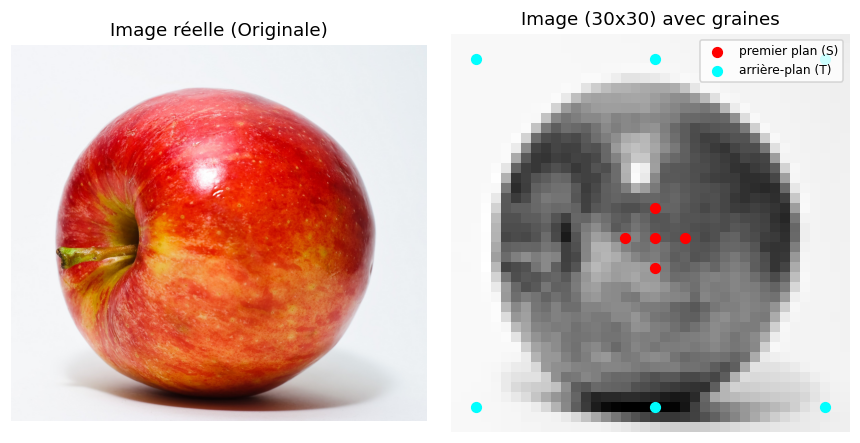

In [2]:
import urllib.request
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# Téléchargement d'image
url = "https://upload.wikimedia.org/wikipedia/commons/1/15/Red_Apple.jpg"
req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})

with urllib.request.urlopen(req) as response, open("apple.jpg", 'wb') as out_file:
    out_file.write(response.read())

# Charger l'image originale en couleur pour la comparaison
img_color = Image.open("apple.jpg")

# Chargement et redimensionnement pour que le graphe NetworkX reste de taille raisonnable
pil_img = img_color.convert("L") # Conversion en niveaux de gris
pil_img = pil_img.resize((40, 40)) # Petite taille pour la rapidité du min-cut
img = np.array(pil_img) / 255.0

# Définition de nouvelles graines adaptées à l'image de la pomme (taille 30x30)
# Centre de la pomme (Foreground)
fg_seeds = [(20, 20), (17, 20), (23, 20), (20, 17), (20, 23)]
# Coins et bords de l'image (Background)
bg_seeds = [(2, 2), (2, 37), (37, 2), (37, 37), (2, 20), (37, 20)]

# Visualisation de l'image réelle et de l'image avec graines côte à côte
fig, ax = plt.subplots(1, 2, figsize=(8, 4))

# Image originale réelle
ax[0].imshow(img_color)
ax[0].set_title("Image réelle (Originale)")
ax[0].axis('off')

# Image en niveaux de gris avec les graines superposées
ax[1].imshow(img, cmap='gray')
ax[1].scatter(*zip(*[(c,r) for r,c in fg_seeds]), c='red', label='premier plan (S)', s=40)
ax[1].scatter(*zip(*[(c,r) for r,c in bg_seeds]), c='cyan', label='arrière-plan (T)', s=40)
ax[1].legend(loc='upper right', fontsize=8)
ax[1].set_title("Image (30x30) avec graines")
ax[1].axis('off')

plt.tight_layout()
plt.show()

### Poids des N-links
On utilise $B_{pq} = \exp\!\left(-\frac{(I_p-I_q)^2}{2\sigma^2}\right)$ : proche de 1 si les intensités sont proches (couper coûte cher), proche de 0 si elles diffèrent (couper un contour est bon marché).

### Poids des T-links
On estime l'intensité moyenne du premier plan et de l'arrière-plan à partir des graines. Plus un pixel ressemble à une classe, plus il est coûteux de l'affecter à l'autre.

In [3]:

def build_graph(img, fg, bg, lam=1.0, sigma=0.2):
    # On s'assure que img est bien un tableau numpy pour pouvoir lire .shape
    img_np = np.asarray(img)
    n, m = img_np.shape
    G = nx.DiGraph()
    mu_f = np.mean([img_np[p] for p in fg])
    mu_b = np.mean([img_np[p] for p in bg])
    INF = 1e6

    for r in range(n):
        for c in range(m):
            p = (r, c)
            Ip = img_np[p]

            # --- T-links : Modélisation du terme régional R(A) ---
            if p in fg:
                G.add_edge('S', p, capacity=INF)
            elif p in bg:
                G.add_edge(p, 'T', capacity=INF)
            else:
                R_p_fg = -np.log(
                    np.exp(-(Ip - mu_f)**2 / (2 * sigma**2)) + 1e-9
                )
                R_p_bg = -np.log(
                    np.exp(-(Ip - mu_b)**2 / (2 * sigma**2)) + 1e-9
                )

                # Coûts régionaux sans lambda
                G.add_edge('S', p, capacity=R_p_bg)
                G.add_edge(p, 'T', capacity=R_p_fg)

            # --- N-links : Modélisation du terme de frontière B(A) ---
            for dr, dc in [(0, 1), (1, 0)]:
                rr, cc = r + dr, c + dc
                if rr < n and cc < m:
                    q = (rr, cc)

                    # Coefficient d'affinité B_pq entre deux pixels voisins
                    B_pq = np.exp(-(Ip - img_np[q])**2 / (2 * sigma**2))

                    # Application de lambda sur le terme de frontière
                    G.add_edge(p, q, capacity=lam * B_pq)
                    G.add_edge(q, p, capacity=lam * B_pq)

    return G


# Récupération sécurisée ou création par défaut
if 'img' not in globals() or not hasattr(img, 'shape'):
    img = np.zeros((30, 30))

if 'fg_seeds' not in globals():
    fg_seeds = [(15, 15), (12, 15), (18, 15), (15, 12), (15, 18)]

if 'bg_seeds' not in globals():
    bg_seeds = [(2, 2), (2, 27), (27, 2), (27, 27), (2, 15), (27, 15)]

G = build_graph(img, set(fg_seeds), set(bg_seeds))

print(f"{G.number_of_nodes()} nœuds, {G.number_of_edges()} arêtes")


1602 nœuds, 9429 arêtes


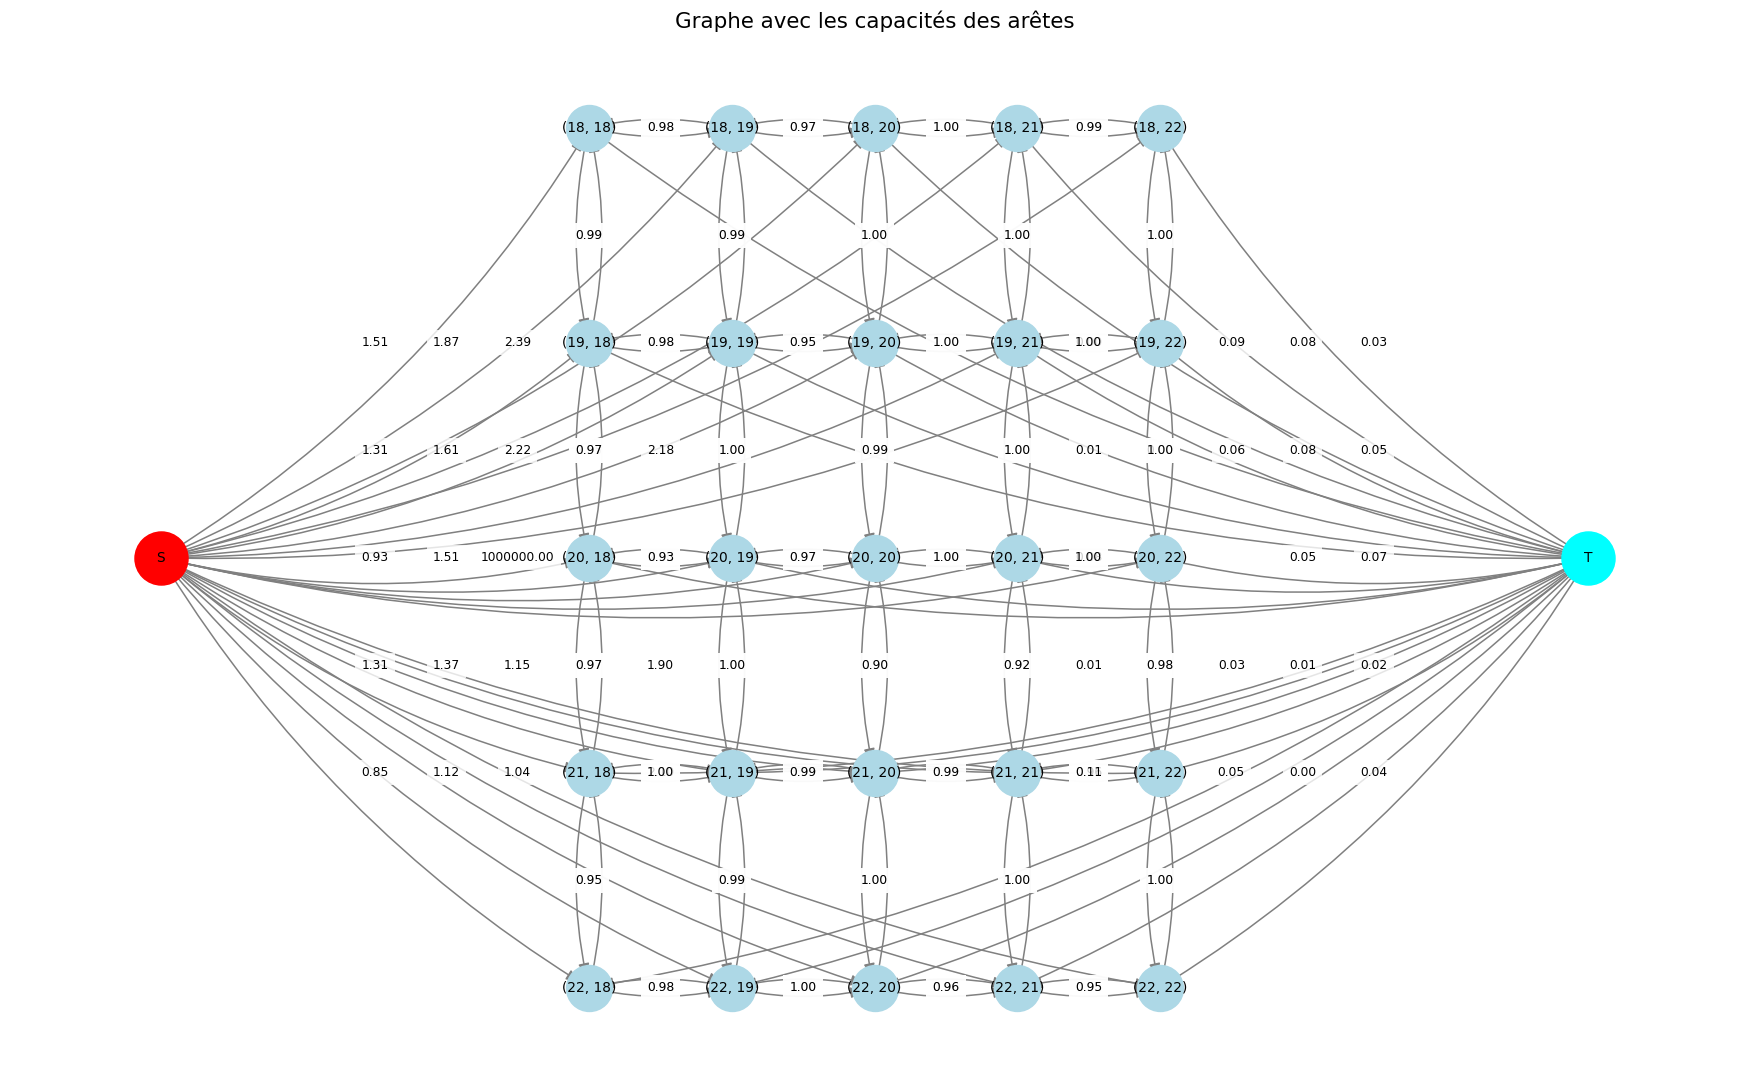

In [4]:
# Création du sous-graphe de visualisation
G_vis = G.subgraph(
    [n for n in G.nodes()
     if isinstance(n, tuple) and 18 <= n[0] <= 22 and 18 <= n[1] <= 22]
    + ['S', 'T']
).copy()

# Définition des positions
pos = {}

for node in G_vis.nodes():
    if isinstance(node, tuple):
        pos[node] = (node[1], -node[0])
    elif node == 'S':
        pos[node] = (15, -20)
    elif node == 'T':
        pos[node] = (25, -20)


# Visualisation des capacités des arêtes
plt.figure(figsize=(16, 10))

edge_labels = {}

for u, v in G_vis.edges():
    if G.has_edge(u, v):
        edge_labels[(u, v)] = f"{G[u][v]['capacity']:.2f}"

# Dessiner les nœuds pixels
nx.draw_networkx_nodes(
    G_vis, pos,
    nodelist=[n for n in G_vis if isinstance(n, tuple)],
    node_color='lightblue',
    node_size=900
)

# Dessiner S à gauche
nx.draw_networkx_nodes(
    G_vis, pos, nodelist=['S'],
    node_color='red', node_size=1200
)

# Dessiner T à droite
nx.draw_networkx_nodes(
    G_vis, pos, nodelist=['T'],
    node_color='cyan', node_size=1200
)

nx.draw_networkx_labels(
    G_vis, pos,
    font_size=9
)

# Dessiner les arêtes
nx.draw_networkx_edges(
    G_vis, pos,
    edgelist=list(G_vis.edges()),
    edge_color='gray',
    arrows=True,
    arrowsize=15,
    connectionstyle='arc3,rad=0.12'
)

# Afficher les capacités
nx.draw_networkx_edge_labels(
    G_vis, pos,
    edge_labels=edge_labels,
    font_size=8,
    label_pos=0.5,
    rotate=False,
    bbox=dict(facecolor='white', edgecolor='none', alpha=0.8)
)

plt.title("Graphe avec les capacités des arêtes", fontsize=14)
plt.axis('off')
plt.tight_layout()
plt.show()

## 3. Calculer la coupe minimale

`networkx.minimum_cut` renvoie la valeur de la coupe et la partition (côté source / côté puits). Les pixels côté **S** forment le premier plan.

Coût de la coupe minimale : 430.89


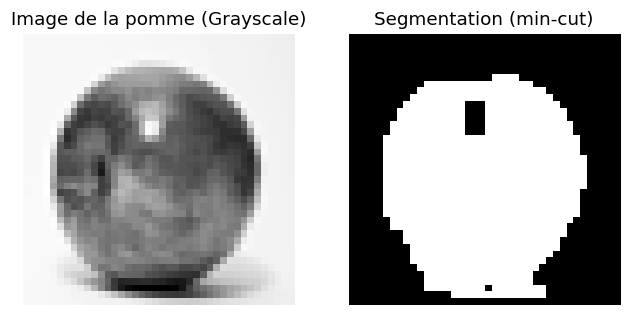

In [5]:
def segment(img, fg, bg, lam=1.0, sigma=0.2):
    G = build_graph(img, set(fg), set(bg), lam, sigma)
    cut_value, (S_side, T_side) = nx.minimum_cut(G, 'S', 'T')
    mask = np.zeros(img.shape, bool)
    for p in S_side:
        if p != 'S': mask[p] = True
    return mask, cut_value

mask, cut_value = segment(img, fg_seeds, bg_seeds)
print("Coût de la coupe minimale :", round(cut_value, 2))

fig, ax = plt.subplots(1, 2, figsize=(7,3.5))
ax[0].imshow(img, cmap='gray'); ax[0].set_title('Image de la pomme (Grayscale)')
ax[1].imshow(mask, cmap='gray'); ax[1].set_title('Segmentation (min-cut)')
for a in ax: a.axis('off')
plt.show()

Coût de la coupe minimale : 430.89


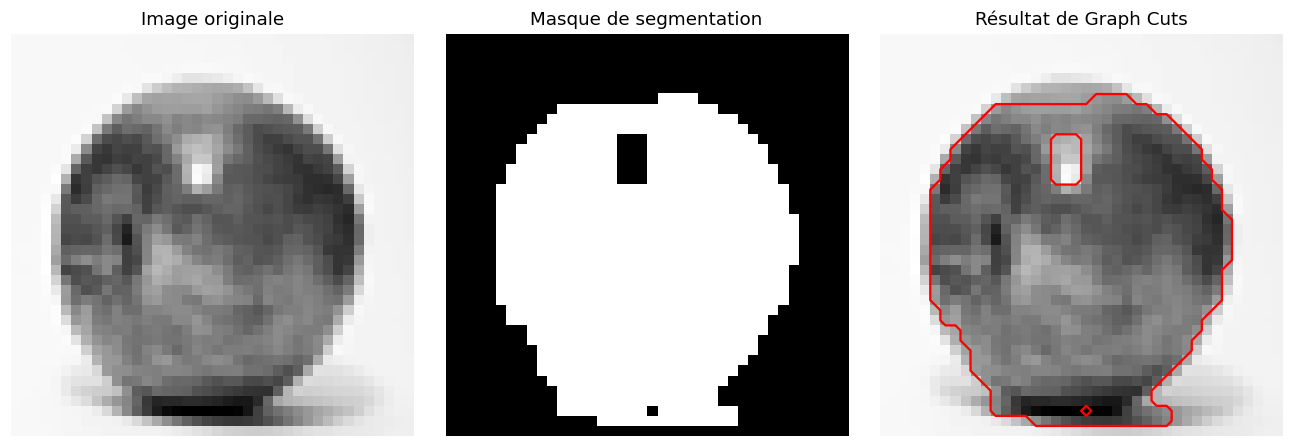

In [6]:
mask, cut_value = segment(img, fg_seeds, bg_seeds)

print("Coût de la coupe minimale :", round(cut_value, 2))

fig, ax = plt.subplots(1, 3, figsize=(12, 4))

# 1. Image originale en niveaux de gris
ax[0].imshow(img, cmap='gray')
ax[0].set_title("Image originale")

# 2. Masque binaire obtenu par Graph Cuts
ax[1].imshow(mask, cmap='gray')
ax[1].set_title("Masque de segmentation")

# 3. Contour de la région segmentée
ax[2].imshow(img, cmap='gray')
ax[2].contour(mask.astype(float), levels=[0.5],
              colors='red', linewidths=1.5)
ax[2].set_title("Résultat de Graph Cuts")

for a in ax:
    a.axis('off')

plt.tight_layout()
plt.show()

## 4. Influence de λ

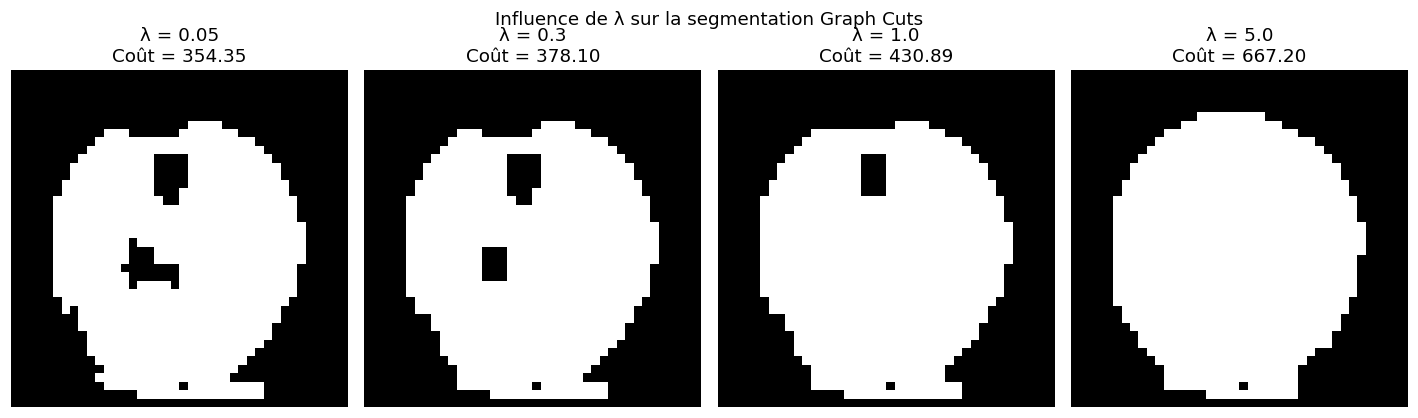

In [7]:
fig, ax = plt.subplots(1, 4, figsize=(13, 4))

lambdas = [0.05, 0.3, 1.0, 5.0]

for a, lam in zip(ax, lambdas):
    m, v = segment(img, fg_seeds, bg_seeds, lam=lam)

    a.imshow(m, cmap='gray')
    a.set_title(f'λ = {lam}\nCoût = {v:.2f}')
    a.axis('off')

plt.suptitle("Influence de λ sur la segmentation Graph Cuts")
plt.tight_layout()
plt.show()

## 5. Lien avec max-flow

Le théorème **max-flow / min-cut** dit que la valeur du flux maximal de S vers T est égale au coût de la coupe minimale. On peut le vérifier : c'est ce qui permet de résoudre le problème efficacement.

In [8]:
# Construction du graphe
G = build_graph(img, set(fg_seeds), set(bg_seeds))

# Calcul du flux maximal
flow_value = nx.maximum_flow_value(G, 'S', 'T')

# Calcul de la coupe minimale
cut_value, _ = nx.minimum_cut(G, 'S', 'T')

# Affichage des résultats
print("=== Vérification du théorème Max-Flow Min-Cut ===")
print(f"Flux maximal  : {flow_value:.6f}")
print(f"Coupe minimale : {cut_value:.6f}")

if np.isclose(flow_value, cut_value):
    print("Vérification réussie : les deux valeurs sont égales.")
else:
    print("Attention : les deux valeurs sont différentes.")

=== Vérification du théorème Max-Flow Min-Cut ===
Flux maximal  : 430.894748
Coupe minimale : 430.894748
Vérification réussie : les deux valeurs sont égales.


## 6.GrabCut (OpenCV)

GrabCut étend le principe : l'utilisateur ne donne qu'un **rectangle**, les couleurs sont modélisées par des **mélanges gaussiens (GMM)**, et on alterne estimation des GMM et min-cut. Exemple sur une image synthétique couleur.

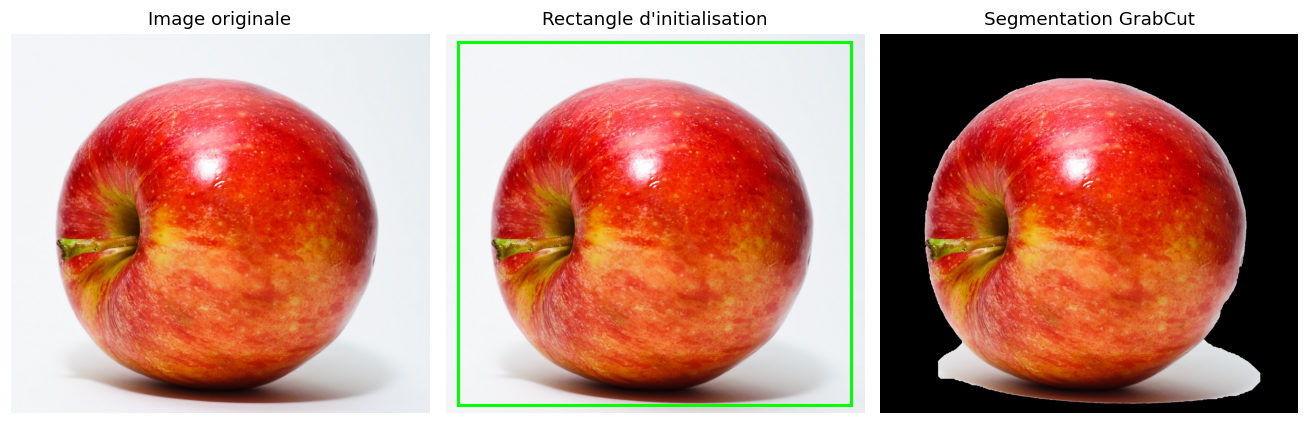

In [9]:
try:
    import cv2
    import numpy as np
    import matplotlib.pyplot as plt

    # Charger l'image originale
    im_bgr = cv2.imread("apple.jpg")

    if im_bgr is None:
        raise FileNotFoundError("L'image apple.jpg est introuvable.")

    h, w, c = im_bgr.shape

    # Définir le rectangle englobant
    rect = (
    int(w * 0.03),
    int(h * 0.02),
    int(w * 0.94),
    int(h * 0.96)
    )

    # Initialiser les masques et les modèles
    mask_gc = np.zeros((h, w), np.uint8)
    bgd = np.zeros((1, 65), np.float64)
    fgd = np.zeros((1, 65), np.float64)

    # Appliquer GrabCut
    cv2.grabCut(
        im_bgr, mask_gc, rect,
        bgd, fgd, 5,
        cv2.GC_INIT_WITH_RECT
    )

    # Extraire le premier plan
    fg_gc = np.where(
        (mask_gc == 1) | (mask_gc == 3), 1, 0
    ).astype(np.uint8)

    # Conversion BGR vers RGB
    im_rgb = cv2.cvtColor(im_bgr, cv2.COLOR_BGR2RGB)

    # Appliquer le masque
    result_gc = im_rgb * fg_gc[..., None]

    # Visualisation
    fig, ax = plt.subplots(1, 3, figsize=(12, 4))

    ax[0].imshow(im_rgb)
    ax[0].set_title("Image originale")

    ax[1].imshow(im_rgb)
    ax[1].add_patch(
        plt.Rectangle(
            (rect[0], rect[1]), rect[2], rect[3],
            fill=False, edgecolor='lime', linewidth=2
        )
    )
    ax[1].set_title("Rectangle d'initialisation")

    ax[2].imshow(result_gc)
    ax[2].set_title("Segmentation GrabCut")

    for a in ax:
        a.axis('off')

    plt.tight_layout()
    plt.show()

except ImportError:
    print("OpenCV non installé : pip install opencv-python")

## 7. Normalized Cuts (N-Cuts) et Comparaison

### Limite du Min-Cut classique
Le critère de coupe minimale classique cherche simplement à minimiser la somme des poids des arêtes coupées. Cela favorise souvent la séparation de très petits groupes de pixels isolés (voire un seul pixel très différent du reste) simplement parce que la somme de ses connexions est numériquement faible.

### Principe des Normalized Cuts (Shi & Malik)
Pour éviter ce biais, les **Normalized Cuts (Coupes Normalisées)** divisent le coût de la coupe par le volume total des connexions de chaque partition avec l'ensemble du graphe :

$$\text{Ncut}(A, B) = \frac{\text{cut}(A, B)}{\text{assoc}(A, V)} + \frac{\text{cut}(A, B)}{\text{assoc}(B, V)}$$

où $\text{assoc}(A, V)$ est la somme des degrés de tous les nœuds de la partition $A$. Ce problème étant NP-complet, on le résout de manière approchée via un problème de valeurs propres généralisées (partitionnement spectral).

Découvrons son application à l'aide de la bibliothèque `scikit-image`.

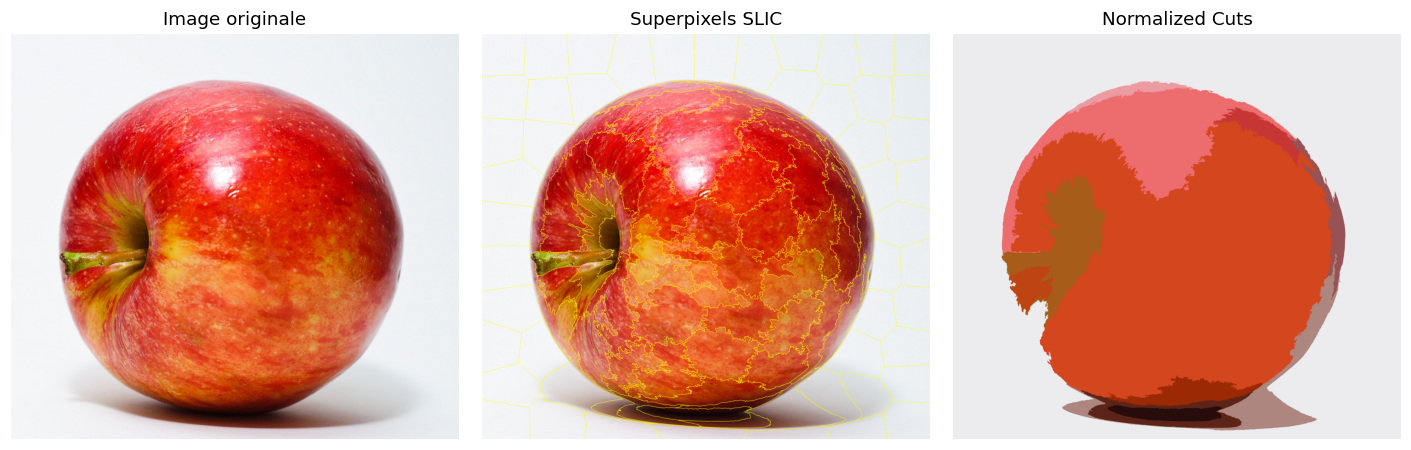

In [10]:
from skimage.segmentation import slic, mark_boundaries
from skimage import graph as skimage_graph
from skimage import color
import numpy as np
import matplotlib.pyplot as plt

# Conversion de l'image en tableau NumPy
img_np = np.array(img_color.convert("RGB"))

# 1. Génération des superpixels avec SLIC
labels = slic(
    img_np,
    compactness=10,
    n_segments=100,
    start_label=1,
    channel_axis=-1
)

# 2. Construction du graphe d'adjacence des régions (RAG)
g_rag = skimage_graph.rag_mean_color(
    img_np, labels, mode='similarity'
)

# 3. Application de Normalized Cuts
ncut_labels = skimage_graph.cut_normalized(
    labels, g_rag, thresh=0.001
)

# 4. Création de l'image segmentée
segmented_ncut = color.label2rgb(
    ncut_labels, img_np, kind='avg', bg_label=0
)

# 5. Visualisation des résultats
fig, ax = plt.subplots(1, 3, figsize=(13, 4))

ax[0].imshow(img_np)
ax[0].set_title("Image originale")

ax[1].imshow(mark_boundaries(img_np, labels))
ax[1].set_title("Superpixels SLIC")

ax[2].imshow(segmented_ncut)
ax[2].set_title("Normalized Cuts")

for a in ax:
    a.axis('off')

plt.tight_layout()
plt.show()

### Comparaison Finale des Approches

Mettons côte à côte les trois techniques de segmentation étudiées sur notre vraie pomme.

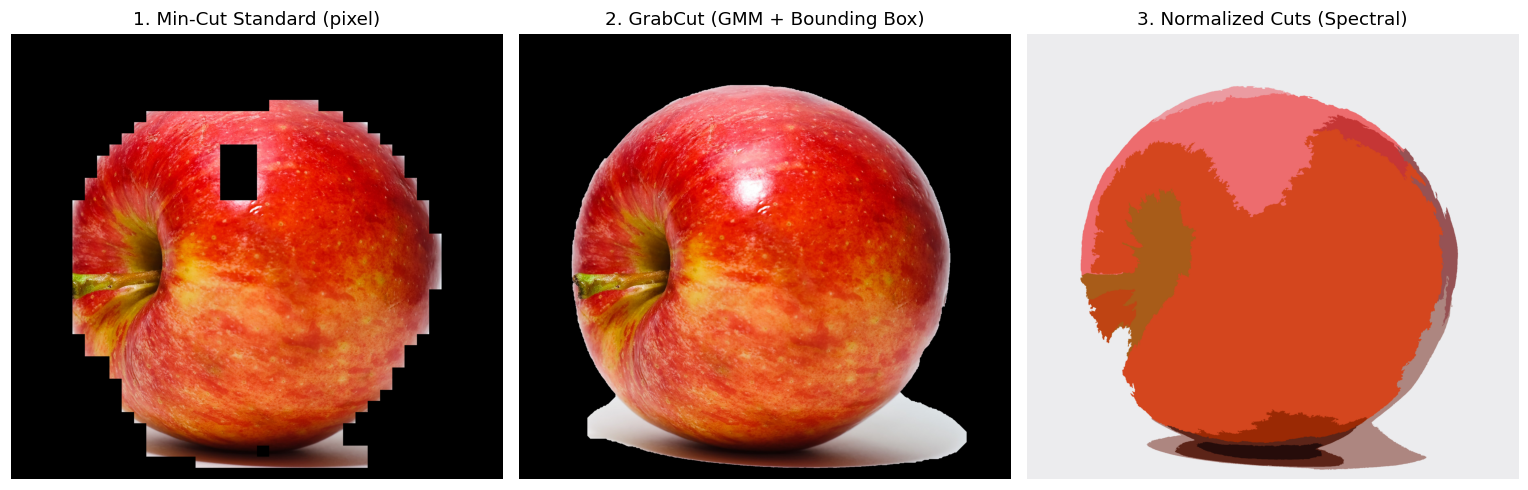

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

fig, ax = plt.subplots(1, 3, figsize=(14, 5))

# Image RGB originale
img_rgb = np.array(img_color.convert("RGB"))

# --- Correction : Redimensionner le masque (40x40) à la taille de l'image d'origine ---
mask_large = np.array(Image.fromarray(mask).resize((img_rgb.shape[1], img_rgb.shape[0]), Image.NEAREST))

# 1. Graph Cuts en couleur avec le masque redimensionné
result_gc_standard = img_rgb * mask_large[..., None]
ax[0].imshow(result_gc_standard)
ax[0].set_title("1. Min-Cut Standard (pixel)")

# 2. GrabCut
ax[1].imshow(im_rgb * fg_gc[..., None])
ax[1].set_title("2. GrabCut (GMM + Bounding Box)")

# 3. Normalized Cuts
ax[2].imshow(segmented_ncut)
ax[2].set_title("3. Normalized Cuts (Spectral)")

for a in ax:
    a.axis('off')

plt.tight_layout()
plt.show()

## 8. Graph Cuts + CNN

### Pourquoi combiner les deux ?
Dans le Graph Cuts classique (sections 2 à 5), le terme régional $R_p$ repose sur un modèle d'apparence **très simple** : une gaussienne sur l'intensité, estimée à partir de quelques graines. Un **CNN** sait apprendre un modèle d'apparence bien plus riche (couleur + contexte spatial local). En revanche, un CNN classe chaque pixel sans imposer de cohérence spatiale explicite : il laisse des trous et des pixels isolés.

L'idée est de se servir de chacun pour ce qu'il fait le mieux :

| Brique | Rôle dans l'énergie $E(A) = \lambda \cdot R(A) + B(A)$ |
|---|---|
| **CNN** | fournit le terme régional : $R_p(\text{"obj"}) = -\ln P_{\text{CNN}}(\text{obj} \mid p)$ et $R_p(\text{"bkg"}) = -\ln\!\big(1 - P_{\text{CNN}}(\text{obj} \mid p)\big)$ |
| **Graph Cuts** | garde le terme de frontière $B_{p,q}$ (calculé sur la couleur) et trouve l'étiquetage **globalement optimal** par min-cut |

Pipeline : `image + graines → CNN → carte de probabilité → T-links → min-cut → segmentation`.

### Le CNN utilisé ici
Il n'existe pas de jeu de données d'entraînement pour « pomme rouge » dans ce notebook, et les réseaux pré-entraînés usuels (DeepLab, etc.) ne connaissent pas cette classe. On entraîne donc un **petit CNN entièrement convolutif directement sur l'image**, en utilisant uniquement les **graines** comme supervision (disques autour des points graines), avec de l'augmentation de données (flips, variations de luminosité, bruit). C'est une approche de type *scribble-supervised*.

> La fonction `graphcut_from_probs` ci-dessous accepte **n'importe quelle carte de probabilité** : on pourrait y brancher la sortie d'un U-Net ou d'un DeepLab pré-entraîné sans rien changer d'autre.

In [12]:
import sys, subprocess, time
try:
    import maxflow                      # solveur max-flow rapide (PyMaxflow)
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "PyMaxflow"])
    import maxflow

import torch, torch.nn as nn, torch.nn.functional as F
from scipy import ndimage as ndi

torch.manual_seed(0); np.random.seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device :", device)

# --- Résolution de travail (le rapport largeur/hauteur de l'image est conservé) ---
WORK = 128
W0, H0 = img_color.size
s = WORK / max(W0, H0)
Ww, Hw = int(round(W0 * s)), int(round(H0 * s))
rgb_w = np.asarray(img_color.convert("RGB").resize((Ww, Hw), Image.BILINEAR), dtype=np.float32) / 255.0

def seeds_to_mask(seeds, shape, grid=40, radius=3):
    # Les graines sont définies sur la grille 40x40 des sections précédentes.
    # On les convertit en petits disques à la résolution de travail pour avoir assez de pixels d'entraînement.
    Hs, Ws = shape
    m = np.zeros(shape, bool)
    yy, xx = np.mgrid[:Hs, :Ws]
    for r, c in seeds:
        cy, cx = (r + 0.5) / grid * Hs, (c + 0.5) / grid * Ws
        m |= (yy - cy) ** 2 + (xx - cx) ** 2 <= radius ** 2
    return m

fg_w = seeds_to_mask(fg_seeds, (Hw, Ww))
bg_w = seeds_to_mask(bg_seeds, (Hw, Ww))
print(f"Image de travail : {Ww}x{Hw} | pixels graines : {fg_w.sum()} (obj) / {bg_w.sum()} (bkg)")

Device : cpu
Image de travail : 128x116 | pixels graines : 141 (obj) / 162 (bkg)


### Architecture et entraînement du CNN
Réseau à 4 blocs de convolutions **dilatées** (dilatations 1, 2, 4, 1) suivis d'une convolution 1×1 : le champ réceptif atteint ~17 pixels, ce qui donne au réseau un peu de contexte spatial sans réduire la résolution (pas de pooling, la sortie a la taille de l'image). La perte est une entropie croisée calculée **uniquement sur les pixels graines**.

In [13]:
class SeedCNN(nn.Module):
    def __init__(self):
        super().__init__()
        def block(cin, cout, d):
            return nn.Sequential(
                nn.Conv2d(cin, cout, 3, padding=d, dilation=d),
                nn.GroupNorm(4, cout),
                nn.ReLU(inplace=True))
        self.body = nn.Sequential(block(3, 16, 1), block(16, 32, 2), block(32, 32, 4), block(32, 16, 1))
        self.head = nn.Conv2d(16, 2, 1)       # 2 classes : 0 = bkg, 1 = obj

    def forward(self, x):
        return self.head(self.body(x))


def train_seed_cnn(rgb, fg_m, bg_m, epochs=300, lr=3e-3, seed=0):
    torch.manual_seed(seed); rng = np.random.RandomState(seed)
    net = SeedCNN().to(device)
    opt = torch.optim.Adam(net.parameters(), lr=lr, weight_decay=1e-4)

    x0 = torch.from_numpy(rgb).permute(2, 0, 1)[None].to(device)
    y0 = torch.full(fg_m.shape, -1, dtype=torch.long)          # -1 = pixel non étiqueté (ignoré)
    y0[torch.from_numpy(bg_m)] = 0
    y0[torch.from_numpy(fg_m)] = 1
    y0 = y0[None].to(device)

    losses = []
    for ep in range(epochs):
        x, y = x0, y0
        # --- augmentation de données ---
        if rng.rand() < .5: x, y = x.flip(3), y.flip(2)
        if rng.rand() < .5: x, y = x.flip(2), y.flip(1)
        gain = 1 + 0.2 * (torch.rand(1, 3, 1, 1, device=device) - .5)
        bias = 0.1 * (torch.rand(1, 1, 1, 1, device=device) - .5)
        x = (x * gain + bias + 0.02 * torch.randn_like(x)).clamp(0, 1)

        loss = F.cross_entropy(net(x), y, ignore_index=-1, label_smoothing=0.1)
        opt.zero_grad(); loss.backward(); opt.step()
        losses.append(loss.item())
    return net, losses


t0 = time.perf_counter()
cnn, losses = train_seed_cnn(rgb_w, fg_w, bg_w)
t_train = time.perf_counter() - t0

cnn.eval()
t0 = time.perf_counter()
with torch.no_grad():
    x = torch.from_numpy(rgb_w).permute(2, 0, 1)[None].to(device)
    prob_cnn = F.softmax(cnn(x), dim=1)[0, 1].cpu().numpy()   # P(obj | pixel) pour chaque pixel
t_infer = time.perf_counter() - t0

print(f"Paramètres : {sum(p.numel() for p in cnn.parameters()):,}")
print(f"Perte finale : {losses[-1]:.3f} | entraînement : {t_train:.1f} s | inférence : {t_infer*1000:.0f} ms")

Paramètres : 19,186
Perte finale : 0.199 | entraînement : 21.2 s | inférence : 19 ms


### Graph Cuts avec les probabilités du CNN
Même construction que `build_graph` (section 2), avec deux différences :
- les **T-links** viennent du CNN : capacité `S→p` = $-\ln(1-P_{\text{CNN}})$ et `p→T` = $-\ln P_{\text{CNN}}$ (probabilités bornées à $[\varepsilon, 1-\varepsilon]$ pour éviter des coûts infinis) ;
- les **N-links** utilisent la distance **couleur RGB** : $B_{pq} = \exp\!\left(-\frac{\|I_p - I_q\|^2}{2\sigma^2}\right)$.

Comme dans la section 2, $\lambda$ pondère le terme de frontière (on retient ici $\lambda = 2$, voir l'étude de $\lambda$ juste après). Le solveur est PyMaxflow (même problème que `networkx.minimum_cut`, mais beaucoup plus rapide : on peut donc travailler en 128 px au lieu de 40 px).

Coût de la coupe minimale : 2437.36 | graph cut : 4 ms


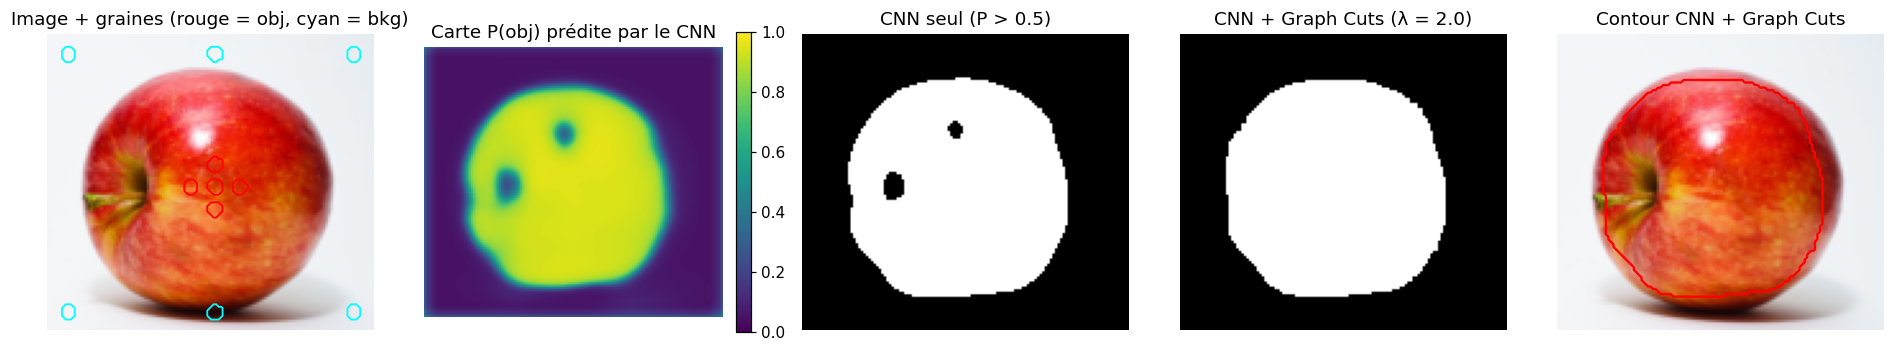

In [14]:
def graphcut_from_probs(prob_fg, rgb, fg_m, bg_m, lam=1.0, sigma=0.2, eps=0.02):
    # Min-cut sur une grille 4-connexe. T-links = carte de probabilité (CNN), N-links = contraste couleur.
    H, W = prob_fg.shape
    INF = 1e9
    p = np.clip(prob_fg, eps, 1 - eps)

    g = maxflow.Graph[float]()
    ids = g.add_grid_nodes((H, W))

    # --- T-links : terme régional R(A) (même convention que build_graph : S->p = coût de "bkg", p->T = coût de "obj") ---
    cap_S = -np.log(1 - p)          # R_p("bkg")
    cap_T = -np.log(p)              # R_p("obj")
    cap_S = np.where(fg_m, INF, np.where(bg_m, 0.0, cap_S))
    cap_T = np.where(bg_m, INF, np.where(fg_m, 0.0, cap_T))
    g.add_grid_tedges(ids, cap_S, cap_T)

    # --- N-links : terme de frontière B(A), voisins droite et bas (arêtes symétriques) ---
    def pair_w(a, b):
        return lam * np.exp(-np.sum((a - b) ** 2, axis=-1) / (2 * sigma ** 2))

    w_right = np.zeros((H, W)); w_right[:, :-1] = pair_w(rgb[:, :-1], rgb[:, 1:])
    w_down  = np.zeros((H, W)); w_down[:-1, :]  = pair_w(rgb[:-1, :], rgb[1:, :])
    g.add_grid_edges(ids, weights=w_right, structure=np.array([[0, 0, 0], [0, 0, 1], [0, 0, 0]]), symmetric=True)
    g.add_grid_edges(ids, weights=w_down,  structure=np.array([[0, 0, 0], [0, 0, 0], [0, 1, 0]]), symmetric=True)

    cut_value = g.maxflow()
    mask = ~g.get_grid_segments(ids)          # True = côté source S = premier plan
    return mask, cut_value


LAM_CNN = 2.0     # valeur retenue d'après l'étude de λ plus bas (comble les petits trous du CNN sans éroder les contours)

t0 = time.perf_counter()
mask_cnn_gc, cut_cnn = graphcut_from_probs(prob_cnn, rgb_w, fg_w, bg_w, lam=LAM_CNN, sigma=0.2)
t_gc = time.perf_counter() - t0
mask_cnn_only = prob_cnn > 0.5

print(f"Coût de la coupe minimale : {cut_cnn:.2f} | graph cut : {t_gc*1000:.0f} ms")

fig, ax = plt.subplots(1, 5, figsize=(17, 3.8))
ax[0].imshow(rgb_w)
ax[0].contour(fg_w, levels=[0.5], colors='red', linewidths=1.2)
ax[0].contour(bg_w, levels=[0.5], colors='cyan', linewidths=1.2)
ax[0].set_title("Image + graines (rouge = obj, cyan = bkg)")

im1 = ax[1].imshow(prob_cnn, cmap='viridis', vmin=0, vmax=1)
ax[1].set_title("Carte P(obj) prédite par le CNN")
plt.colorbar(im1, ax=ax[1], fraction=0.046, pad=0.04)

ax[2].imshow(mask_cnn_only, cmap='gray')
ax[2].set_title("CNN seul (P > 0.5)")

ax[3].imshow(mask_cnn_gc, cmap='gray')
ax[3].set_title(f"CNN + Graph Cuts (λ = {LAM_CNN})")

ax[4].imshow(rgb_w)
ax[4].contour(mask_cnn_gc.astype(float), levels=[0.5], colors='red', linewidths=1.5)
ax[4].set_title("Contour CNN + Graph Cuts")

for a in ax: a.axis('off')
plt.tight_layout(); plt.show()

### Influence de λ avec les T-links du CNN
Même expérience que la section 4, mais sur le modèle CNN + Graph Cuts : $\lambda$ faible → on suit la carte du CNN telle quelle ; $\lambda$ élevé → on impose des frontières plus lisses, qui suivent les contours de l'image.

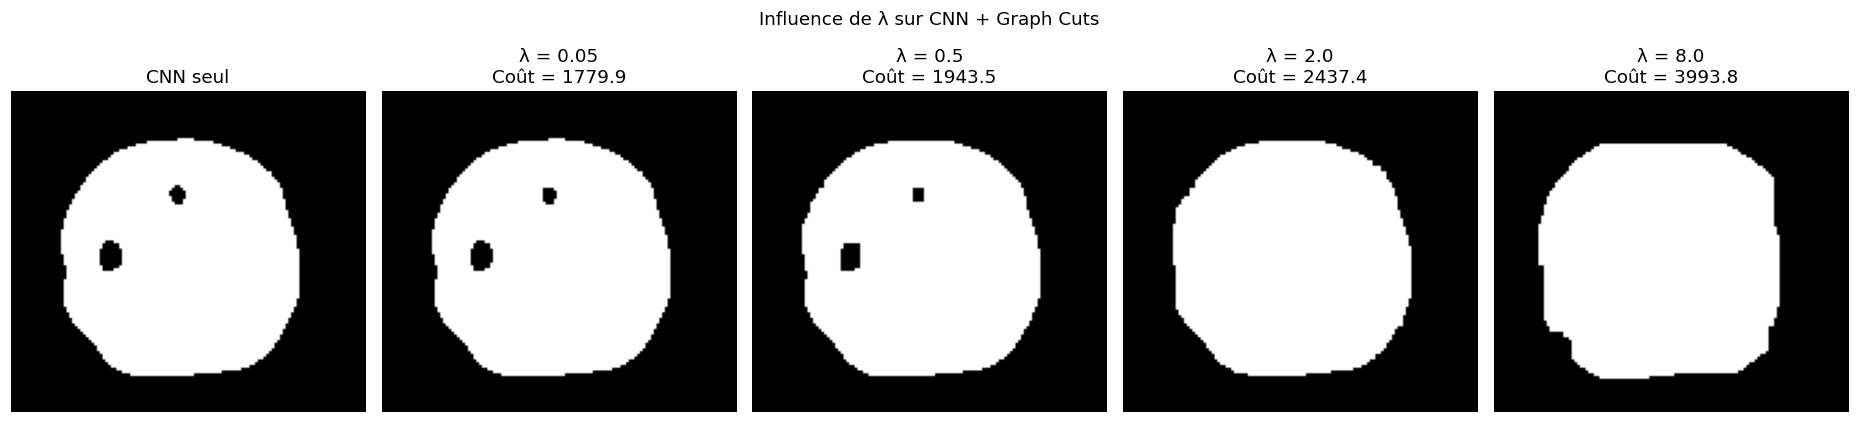

In [15]:
lambdas = [0.05, 0.5, 2.0, 8.0]
fig, ax = plt.subplots(1, 5, figsize=(17, 3.6))

ax[0].imshow(mask_cnn_only, cmap='gray'); ax[0].set_title("CNN seul")
for a, lam in zip(ax[1:], lambdas):
    m, v = graphcut_from_probs(prob_cnn, rgb_w, fg_w, bg_w, lam=lam, sigma=0.2)
    a.imshow(m, cmap='gray')
    a.set_title(f"λ = {lam}\nCoût = {v:.1f}")
for a in ax: a.axis('off')

plt.suptitle("Influence de λ sur CNN + Graph Cuts", y=1.06)
plt.tight_layout(); plt.show()

## 9. Comparaison globale des approches

On compare maintenant **les cinq méthodes** sur la même image :

1. **Min-Cut standard** (pixel, niveaux de gris, graines) — sections 2 à 5
2. **GrabCut** (GMM + rectangle) — section 6
3. **Normalized Cuts** (spectral, sur superpixels) — section 7
4. **CNN seul** (entraîné sur les graines) — section 8
5. **CNN + Graph Cuts** — section 8

### Protocole
- Toutes les segmentations sont ramenées à une **même résolution d'évaluation** (256 px de large).
- Il n'y a pas de masque vérité-terrain fourni avec l'image. On construit donc une **référence approchée** : seuillage d'Otsu sur la *saturation* (pomme rouge saturée vs fond blanc/gris), remplissage des trous, ouverture morphologique (retire l'ombre fine sous la pomme), plus grande composante connexe. C'est une **référence de comparaison, pas une vérité parfaite** : les scores servent à classer les méthodes entre elles. Pour une évaluation rigoureuse, remplacez `ref_mask` par un masque dessiné à la main.
- **Normalized Cuts** est non supervisé et produit plusieurs régions : pour obtenir un masque binaire, chaque région est affectée à l'objet ou au fond selon que sa couleur moyenne est plus proche de celle des graines objet ou des graines fond.
- Les temps sont mesurés en ré-exécutant chaque méthode (CPU/GPU de la session). Pour le CNN, le temps inclut l'entraînement.

Métriques : IoU $= \frac{|P \cap R|}{|P \cup R|}$, Dice $= \frac{2|P \cap R|}{|P| + |R|}$, précision $= \frac{|P \cap R|}{|P|}$, rappel $= \frac{|P \cap R|}{|R|}$ ($P$ = prédiction, $R$ = référence).

In [16]:
from skimage.color import rgb2hsv
from skimage.filters import threshold_otsu
from skimage.morphology import disk
from skimage.segmentation import slic
from skimage import graph as skimage_graph
import pandas as pd
from IPython.display import display

# ------------- Résolution commune d'évaluation -------------
EV_W = 256
EV_H = int(round(EV_W * H0 / W0))
rgb_eval = np.asarray(img_color.convert("RGB").resize((EV_W, EV_H), Image.BILINEAR))

def to_eval(m):
    # masque booléen de n'importe quelle taille -> résolution d'évaluation
    return np.array(Image.fromarray(m.astype(np.uint8) * 255).resize((EV_W, EV_H), Image.NEAREST)) > 127

# ------------- Référence approchée (saturation + Otsu) -------------
sat = rgb2hsv(rgb_eval)[..., 1]
ref_mask = ndi.binary_fill_holes(sat > threshold_otsu(sat))
# ouverture avec un grand disque : supprime l'ombre fine sous la pomme et le bruit
ref_mask = ndi.binary_opening(np.pad(ref_mask, 15), structure=disk(10))[15:-15, 15:-15]
lab_ref, n_ref = ndi.label(ref_mask)
if n_ref > 1:                                   # on garde la plus grande composante
    sizes = ndi.sum(ref_mask, lab_ref, range(1, n_ref + 1))
    ref_mask = lab_ref == (1 + int(np.argmax(sizes)))
ref_mask = ndi.binary_fill_holes(ref_mask)

# ------------- Méthodes (chacune renvoie un masque booléen) -------------
def run_mincut():
    return segment(img, fg_seeds, bg_seeds)[0]                 # section 3 (grille 40x40)

def run_grabcut():
    m = np.zeros(im_bgr.shape[:2], np.uint8)
    bgd, fgd = np.zeros((1, 65)), np.zeros((1, 65))
    cv2.grabCut(im_bgr, m, rect, bgd, fgd, 5, cv2.GC_INIT_WITH_RECT)  # section 6
    return (m == 1) | (m == 3)

def run_ncut():
    rgb_full = np.array(img_color.convert("RGB"))
    lab = slic(rgb_full, compactness=10, n_segments=100, start_label=1, channel_axis=-1)
    rag = skimage_graph.rag_mean_color(rgb_full, lab, mode='similarity')
    nl = skimage_graph.cut_normalized(lab, rag, thresh=0.001)        # section 7
    # binarisation : région -> obj si sa couleur moyenne est plus proche des graines obj que des graines bkg
    c_fg, c_bg = rgb_w[fg_w].mean(0), rgb_w[bg_w].mean(0)
    out = np.zeros(nl.shape, bool)
    for l in np.unique(nl):
        col = rgb_full[nl == l].mean(0) / 255.0
        out[nl == l] = np.linalg.norm(col - c_fg) < np.linalg.norm(col - c_bg)
    return out

def timed(fn):
    t0 = time.perf_counter(); m = fn(); return to_eval(m), time.perf_counter() - t0

results = {}
results["Min-Cut (pixel)"]   = timed(run_mincut)
results["GrabCut"]           = timed(run_grabcut)
results["Normalized Cuts"]   = timed(run_ncut)
results["CNN seul"]          = (to_eval(mask_cnn_only), t_train + t_infer)
results["CNN + Graph Cuts"]  = (to_eval(mask_cnn_gc),   t_train + t_infer + t_gc)

# ------------- Métriques -------------
def seg_metrics(pred, ref):
    tp = np.sum(pred & ref); fp = np.sum(pred & ~ref); fn = np.sum(~pred & ref)
    return dict(IoU=tp / (tp + fp + fn), Dice=2 * tp / (2 * tp + fp + fn),
                Précision=tp / max(tp + fp, 1), Rappel=tp / max(tp + fn, 1))

rows = {}
for name, (m, dt) in results.items():
    rows[name] = {**seg_metrics(m, ref_mask), "Temps (s)": dt}
df = pd.DataFrame(rows).T

print("Tableau comparatif (référence approchée : saturation + Otsu)")
display(df.style.format({"IoU": "{:.3f}", "Dice": "{:.3f}", "Précision": "{:.3f}", "Rappel": "{:.3f}", "Temps (s)": "{:.2f}"})
          .highlight_max(subset=["IoU", "Dice", "Précision", "Rappel"], color="#c8e6c9")
          .highlight_min(subset=["Temps (s)"], color="#c8e6c9"))

best = df["IoU"].idxmax()
print(f"\n>>> Meilleur IoU : {best} ({df.loc[best, 'IoU']:.3f})")

Tableau comparatif (référence approchée : saturation + Otsu)


,IoU,Dice,Précision,Rappel,Temps (s)
Min-Cut (pixel),0.915,0.956,0.954,0.957,0.25
GrabCut,0.862,0.926,0.862,1.000,32.01
Normalized Cuts,0.959,0.979,0.977,0.982,29.32
CNN seul,0.842,0.914,1.000,0.842,21.20
CNN + Graph Cuts,0.861,0.926,1.000,0.861,21.21



>>> Meilleur IoU : Normalized Cuts (0.959)


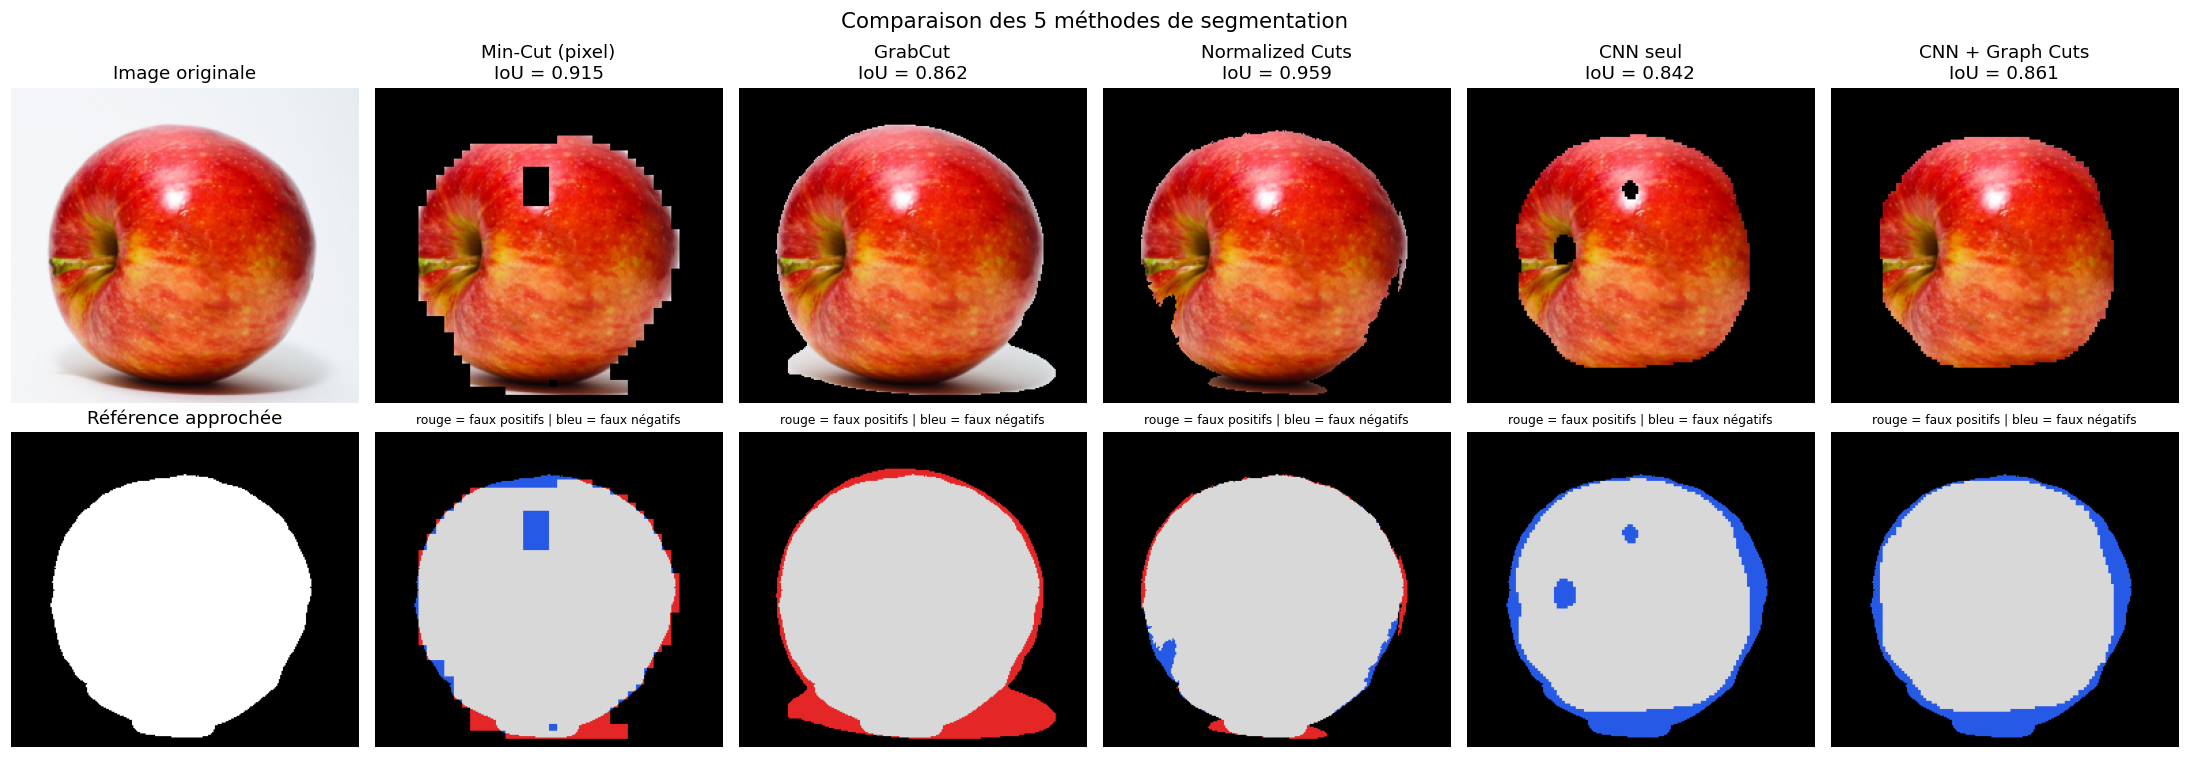

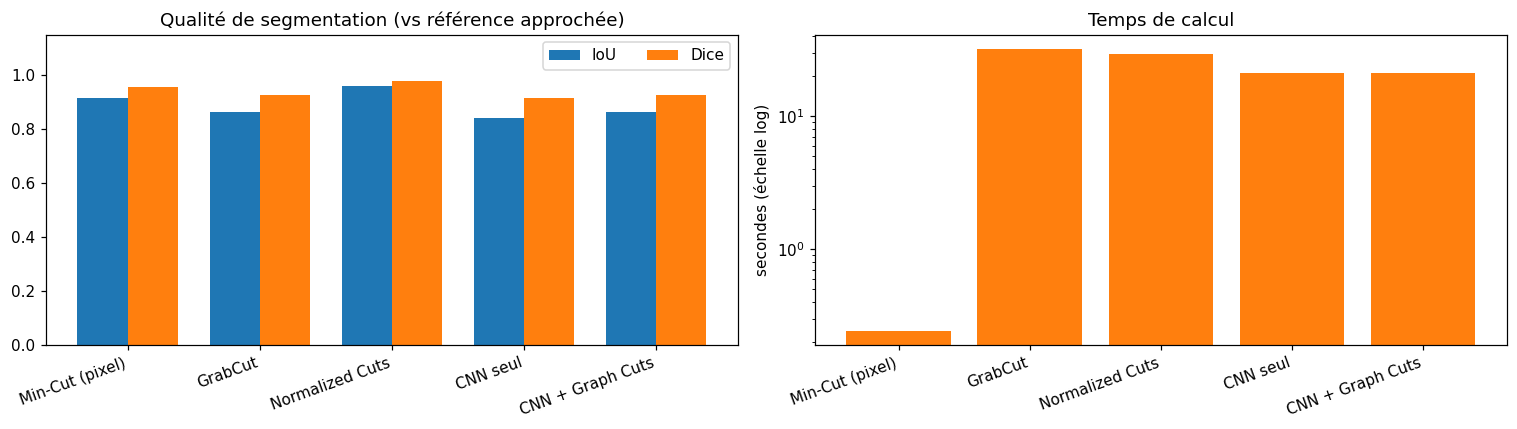

In [17]:
# ------------- Comparaison visuelle : résultats (ligne 1) et cartes d'erreur (ligne 2) -------------
names = list(results.keys())
fig, ax = plt.subplots(2, 6, figsize=(20, 7.2))

ax[0, 0].imshow(rgb_eval); ax[0, 0].set_title("Image originale")
ax[1, 0].imshow(ref_mask, cmap='gray'); ax[1, 0].set_title("Référence approchée")

for j, name in enumerate(names, start=1):
    m = results[name][0]
    ax[0, j].imshow(rgb_eval * m[..., None])
    ax[0, j].set_title(f"{name}\nIoU = {df.loc[name, 'IoU']:.3f}")

    err = np.zeros(m.shape + (3,))
    err[m & ref_mask]  = (0.85, 0.85, 0.85)    # bien classé (obj)  : gris clair
    err[m & ~ref_mask] = (0.90, 0.15, 0.15)    # faux positif       : rouge
    err[~m & ref_mask] = (0.15, 0.35, 0.90)    # faux négatif       : bleu
    ax[1, j].imshow(err)
    ax[1, j].set_title("rouge = faux positifs | bleu = faux négatifs", fontsize=8)

for a in ax.ravel(): a.axis('off')
plt.suptitle("Comparaison des 5 méthodes de segmentation", fontsize=14)
plt.tight_layout(); plt.show()

# ------------- Scores et temps -------------
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
xpos = np.arange(len(names)); bw = 0.38
ax[0].bar(xpos - bw / 2, df["IoU"],  bw, label="IoU")
ax[0].bar(xpos + bw / 2, df["Dice"], bw, label="Dice")
ax[0].set_xticks(xpos); ax[0].set_xticklabels(names, rotation=20, ha='right')
ax[0].set_ylim(0, 1.15); ax[0].set_title("Qualité de segmentation (vs référence approchée)"); ax[0].legend(loc='upper right', ncol=2)

ax[1].bar(xpos, df["Temps (s)"], color="tab:orange")
ax[1].set_yscale("log"); ax[1].set_xticks(xpos); ax[1].set_xticklabels(names, rotation=20, ha='right')
ax[1].set_ylabel("secondes (échelle log)"); ax[1].set_title("Temps de calcul")
plt.tight_layout(); plt.show()

### Comparaison qualitative

| | **Min-Cut (pixel)** | **GrabCut** | **Normalized Cuts** | **CNN seul** | **CNN + Graph Cuts** |
|---|---|---|---|---|---|
| **Interaction** | graines (points) | rectangle | aucune (non supervisé) | graines (pour entraîner) | graines (pour entraîner) |
| **Information utilisée** | intensité (gris) | couleur RGB | couleur moyenne de superpixels | couleur + contexte local (champ réceptif) | couleur + contexte local + contraste aux frontières |
| **Modèle d'apparence** | gaussienne par classe | mélange de gaussiennes (GMM) | affinités entre régions | réseau convolutif appris | réseau convolutif appris |
| **Cohérence spatiale** | oui (terme $B$) | oui (terme $B$) | oui (graphe de régions) | **non explicite** | oui (terme $B$) |
| **Optimisation** | min-cut exact | min-cut itéré (minimum local) | relaxation spectrale (approximation) | descente de gradient | entraînement + min-cut exact |
| **Sortie** | binaire | binaire | multi-régions (à binariser) | binaire (carte de probabilité) | binaire |
| **Atouts** | simple, optimum global, très interprétable | peu d'interaction, bon sur couleurs distinctes | aucune graine, vue globale de l'image | modèle d'apparence riche | probabilités riches **et** frontières propres |
| **Limites** | modèle trop pauvre, texture/ombres mal gérées | dépend du rectangle et des couleurs du fond | pas de sémantique, coût élevé, régions à interpréter | trous et pixels isolés, sensible au sur-apprentissage sur peu de graines | entraînement + réglage de $\lambda$, $\sigma$ |

### Lecture des résultats
- **Min-Cut vs CNN + Graph Cuts** : le cadre énergétique est identique (même terme $B$, même min-cut). Seule la source du terme régional change (gaussienne sur l'intensité contre probabilité apprise par CNN). L'écart de score entre les deux mesure donc directement l'apport du CNN.
- **CNN seul vs CNN + Graph Cuts** : l'écart mesure l'apport de la régularisation par Graph Cuts sur une même carte de probabilité. C'est l'argument central de l'hybridation : le CNN apporte l'apparence, le Graph Cuts apporte la cohérence spatiale et l'alignement sur les contours.
- **GrabCut** est la méthode classique la plus proche de CNN + Graph Cuts (modèle d'apparence couleur + min-cut), avec une interaction plus légère (un rectangle).
- **Normalized Cuts** est le seul à ne pas exploiter de graines pour segmenter : il propose une partition de l'image, qu'il faut ensuite interpréter, ce qui explique en partie son score.
- Côté **coût**, les méthodes à base de CNN paient l'entraînement ; Graph Cuts seul et GrabCut sont quasi instantanés sur cette image.
- **À retenir sur cette image** (cartes d'erreur ci-dessus) : avec seulement une dizaine de points graines, le CNN apprend surtout « rouge contre blanc/ombre ». Il reste prudent près des bords (précision élevée, rappel plus faible : anneau bleu) et classe les reflets blancs comme du fond. Le Graph Cuts comble les reflets (via $\lambda$) et lisse la frontière, mais ne peut pas corriger un bord que le CNN a mal localisé. Davantage de graines près des contours, ou un CNN pré-entraîné sur la classe visée, sont les leviers naturels d'amélioration.

> Les valeurs exactes (scores, temps) dépendent de l'image, des graines, de la référence approchée et de la machine : se référer au tableau généré plus haut.